# 🇵🇰 Pakistan Sign Language (PSL) Deep Learning Recognition System
**Author:** Muhammad Rayyan Tariq (BSCS Section 7A | Roll No: SU92-BSCSM-F23-237)  
**Project Objective:** End-to-end image classification of 37 Urdu/PSL alphabet and letter signs using two distinct architectures:
1. **Model A:** Custom Convolutional Neural Network (CNN) built entirely from scratch.
2. **Model B:** Transfer Learning using MobileNetV2 (pre-trained on ImageNet with frozen feature extractor).

Step 1: Mount Google Drive in Colab

In [ ]:
from google.colab import drive
import os

# Mount your Google Drive
drive.mount('/content/drive')

# Create a project folder in your Drive (if it doesn't already exist)
project_dir = '/content/drive/My Drive/PSL_DeepLearning_Project'
os.makedirs(project_dir, exist_ok=True)

print(f"Directory ready at: {project_dir}")

Mounted at /content/drive
Directory ready at: /content/drive/My Drive/PSL_DeepLearning_Project


Step 2: Upload the Dataset Zip Manually to Drive

Navigate to the folder that was just created: My Drive/PSL_DeepLearning_Project.

Drag and drop the downloaded dataset-pakistani-sign-language.zip file directly from your computer into that folder on Google Drive.


Step 3: Unzip Directly from Drive inside Colab

In [ ]:
import zipfile
import os

# Paths
drive_zip_path = '/content/drive/My Drive/PSL_DeepLearning_Project/dataset-pakistani-sign-language.zip'
extract_path = '/content/psl_data'

# Unzip
print("Extracting dataset from Google Drive...")
with zipfile.ZipFile(drive_zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Dataset successfully extracted to: {extract_path}")

# Verify extracted contents
print("Dataset folders:", os.listdir(extract_path))

Extracting dataset from Google Drive...
Dataset successfully extracted to: /content/psl_data
Dataset folders: ['dataset']


Custom CNN from Scratch

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import os

# 1. Define paths and parameters
data_dir = '/content/psl_data/dataset'
BATCH_SIZE = 32
IMG_SIZE = (128, 128)  # 128x128 is optimal for fast training on Colab CPU/GPU
EPOCHS = 10

# 2. Load dataset with 80-20 train/validation split
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"Total Classes Found: {num_classes}")

# Optimize dataset performance using buffering
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# 3. Build Custom CNN from Scratch (Model A)
model_scratch = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification Head
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model_scratch.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_scratch.summary()

# 4. Train Model A
print("\n--- Training Custom CNN from Scratch ---")
history_scratch = model_scratch.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

# Save model weights
model_scratch.save('/content/drive/My Drive/PSL_DeepLearning_Project/psl_custom_cnn.h5')
print("Custom CNN model trained and saved to Google Drive!")

Found 7242 files belonging to 37 classes.
Using 5794 files for training.
Found 7242 files belonging to 37 classes.
Using 1448 files for validation.
Total Classes Found: 37


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,491,621 (32.39 MB)

 Trainable params: 8,491,621 (32.39 MB)

 Non-trainable params: 0 (0.00 B)


--- Training Custom CNN from Scratch ---
Epoch 1/10
182/182 ━━━━━━━━━━━━━━━━━━━━ 25s 91ms/step - accuracy: 0.2570 - loss: 2.6955 - val_accuracy: 0.7597 - val_loss: 0.8482
Epoch 2/10
182/182 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.7233 - loss: 0.8891 - val_accuracy: 0.9330 - val_loss: 0.2657
Epoch 3/10
182/182 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.8466 - loss: 0.4648 - val_accuracy: 0.9586 - val_loss: 0.1556
Epoch 4/10
182/182 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.8966 - loss: 0.3146 - val_accuracy: 0.9655 - val_loss: 0.0967
Epoch 5/10
182/182 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.9258 - loss: 0.2296 - val_accuracy: 0.9751 - val_loss: 0.0795
Epoch 6/10
182/182 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.9408 - loss: 0.1750 - val_accuracy: 0.9910 - val_loss: 0.0386
Epoch 7/10
182/182 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.9489 - loss: 0.1482 - val_accuracy: 0.9876 - val_loss: 0.0383
Epoch 8/10
182/182 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step -

Custom CNN model trained and saved to Google Drive!


Model 2: Transfer Learning (MobileNetV2).

In [ ]:
from tensorflow.keras.applications import MobileNetV2

# 1. Load Pre-trained MobileNetV2 (Freeze Base Layers)
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_model.trainable = False  # Freeze feature extractor

# 2. Attach Custom Classification Head
model_transfer = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./127.5, offset=-1), # MobileNetV2 expects pixel values normalized between [-1, 1]
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model_transfer.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_transfer.summary()

# 3. Train Model B (Transfer Learning)
print("\n--- Training Transfer Learning Model (MobileNetV2) ---")
history_transfer = model_transfer.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6  # Transfer learning converges extremely fast
)

# Save transfer learning model weights
model_transfer.save('/content/drive/My Drive/PSL_DeepLearning_Project/psl_transfer_learning.h5')
print("Transfer Learning model trained and saved to Google Drive!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 37)             │         4,773 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,426,725 (9.26 MB)

 Trainable params: 168,741 (659.14 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


--- Training Transfer Learning Model (MobileNetV2) ---
Epoch 1/6
182/182 ━━━━━━━━━━━━━━━━━━━━ 23s 71ms/step - accuracy: 0.8388 - loss: 0.6576 - val_accuracy: 0.9938 - val_loss: 0.0449
Epoch 2/6
182/182 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9895 - loss: 0.0514 - val_accuracy: 0.9972 - val_loss: 0.0178
Epoch 3/6
182/182 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9945 - loss: 0.0254 - val_accuracy: 0.9924 - val_loss: 0.0224
Epoch 4/6
182/182 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9978 - loss: 0.0158 - val_accuracy: 0.9993 - val_loss: 0.0049
Epoch 5/6
182/182 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9990 - loss: 0.0094 - val_accuracy: 0.9993 - val_loss: 0.0041
Epoch 6/6
182/182 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9981 - loss: 0.0086 - val_accuracy: 0.9993 - val_loss: 0.0035


Transfer Learning model trained and saved to Google Drive!


Generating the Network Diagrams

In [ ]:
from tensorflow.keras.utils import plot_model

# Generate and save architecture diagram for Custom CNN (Model A)
plot_model(
    model_scratch,
    to_file='/content/drive/My Drive/PSL_DeepLearning_Project/custom_cnn_diagram.png',
    show_shapes=True,
    show_layer_names=True,
    dpi=300
)

# Generate and save architecture diagram for Transfer Learning (Model B)
plot_model(
    model_transfer,
    to_file='/content/drive/My Drive/PSL_DeepLearning_Project/transfer_learning_diagram.png',
    show_shapes=True,
    show_layer_names=True,
    dpi=300
)

print("Both network architecture diagrams generated and saved to Google Drive!")

Both network architecture diagrams generated and saved to Google Drive!


Generate Training Evaluation Graphs (Loss & Accuracy Curves)

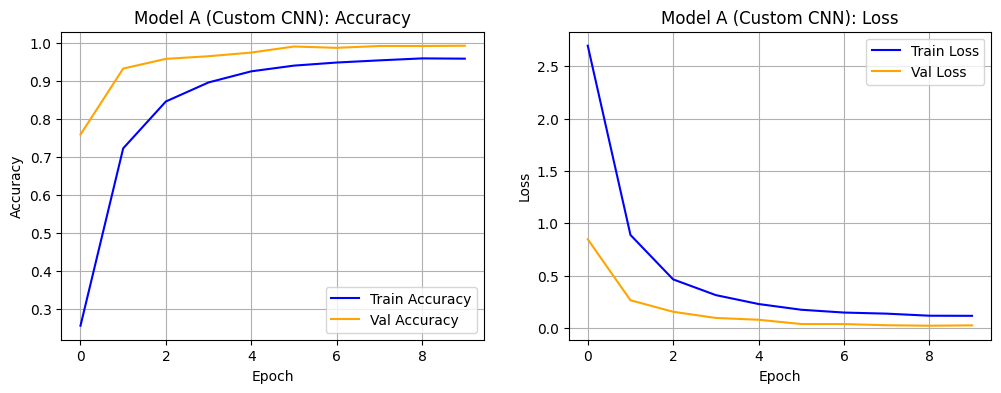

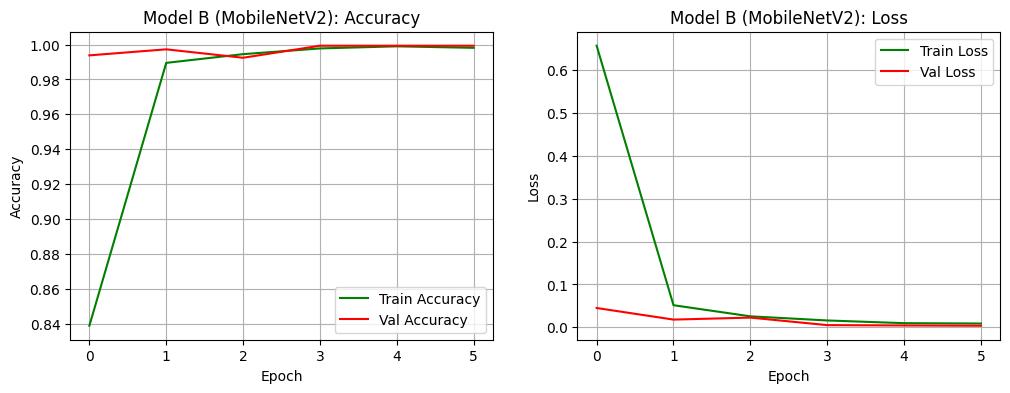

Evaluation graphs saved to Google Drive!


In [ ]:
import matplotlib.pyplot as plt

# 1. Plot Custom CNN (Model A) Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history_scratch.history['accuracy'], label='Train Accuracy', color='blue')
ax1.plot(history_scratch.history['val_accuracy'], label='Val Accuracy', color='orange')
ax1.set_title('Model A (Custom CNN): Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

ax2.plot(history_scratch.history['loss'], label='Train Loss', color='blue')
ax2.plot(history_scratch.history['val_loss'], label='Val Loss', color='orange')
ax2.set_title('Model A (Custom CNN): Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.savefig('/content/drive/My Drive/PSL_DeepLearning_Project/custom_cnn_evaluation.png', dpi=300)
plt.show()

# 2. Plot Transfer Learning (Model B) Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history_transfer.history['accuracy'], label='Train Accuracy', color='green')
ax1.plot(history_transfer.history['val_accuracy'], label='Val Accuracy', color='red')
ax1.set_title('Model B (MobileNetV2): Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

ax2.plot(history_transfer.history['loss'], label='Train Loss', color='green')
ax2.plot(history_transfer.history['val_loss'], label='Val Loss', color='red')
ax2.set_title('Model B (MobileNetV2): Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.savefig('/content/drive/My Drive/PSL_DeepLearning_Project/transfer_learning_evaluation.png', dpi=300)
plt.show()

print("Evaluation graphs saved to Google Drive!")

Architecture Diagrams

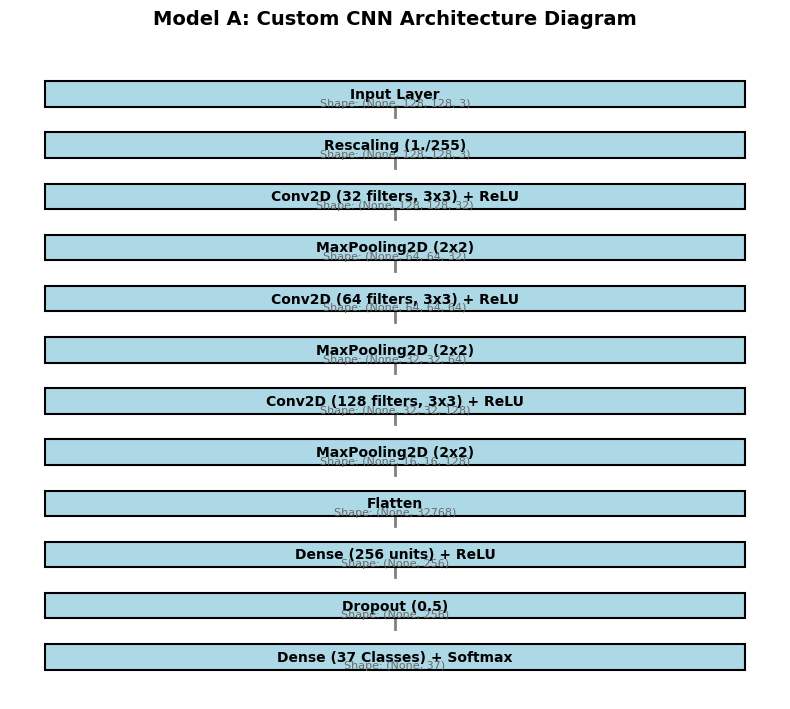

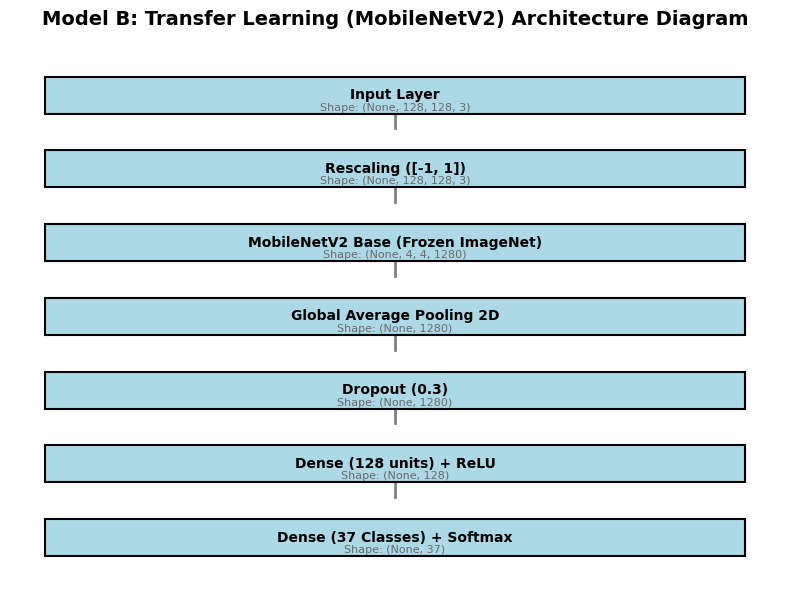

Exact model architecture diagrams saved to Google Drive successfully!


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def plot_model_architecture(layer_names, layer_shapes, filename, title):
    fig, ax = plt.subplots(figsize=(8, max(6, len(layer_names) * 0.6)))
    ax.axis('off')

    y_positions = range(len(layer_names), 0, -1)

    for i, (name, shape, y) in enumerate(zip(layer_names, layer_shapes, y_positions)):
        # Draw box for layer using patches module
        rect = patches.Rectangle((0.2, y - 0.3), 0.6, 0.5, facecolor='lightblue', edgecolor='black', lw=1.5, zorder=3)
        ax.add_patch(rect)

        # Layer text
        ax.text(0.5, y - 0.05, f"{name}", ha='center', va='center', fontsize=10, weight='bold', zorder=4)
        ax.text(0.5, y - 0.22, f"Shape: {shape}", ha='center', va='center', fontsize=8, color='dimgray', zorder=4)

        # Draw connecting line to next layer
        if i < len(layer_names) - 1:
            ax.plot([0.5, 0.5], [y - 0.3, y - 0.5], color='gray', lw=2, zorder=2)

    plt.title(title, fontsize=14, weight='bold', pad=20)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

# --- Model A: Custom CNN Layers ---
model_a_layers = [
    "Input Layer",
    "Rescaling (1./255)",
    "Conv2D (32 filters, 3x3) + ReLU",
    "MaxPooling2D (2x2)",
    "Conv2D (64 filters, 3x3) + ReLU",
    "MaxPooling2D (2x2)",
    "Conv2D (128 filters, 3x3) + ReLU",
    "MaxPooling2D (2x2)",
    "Flatten",
    "Dense (256 units) + ReLU",
    "Dropout (0.5)",
    "Dense (37 Classes) + Softmax"
]
model_a_shapes = [
    "(None, 128, 128, 3)", "(None, 128, 128, 3)",
    "(None, 128, 128, 32)", "(None, 64, 64, 32)",
    "(None, 64, 64, 64)", "(None, 32, 32, 64)",
    "(None, 32, 32, 128)", "(None, 16, 16, 128)",
    "(None, 32768)", "(None, 256)",
    "(None, 256)", "(None, 37)"
]

plot_model_architecture(
    model_a_layers, model_a_shapes,
    '/content/drive/My Drive/PSL_DeepLearning_Project/model_a_architecture.png',
    'Model A: Custom CNN Architecture Diagram'
)

# --- Model B: Transfer Learning (MobileNetV2) Layers ---
model_b_layers = [
    "Input Layer",
    "Rescaling ([-1, 1])",
    "MobileNetV2 Base (Frozen ImageNet)",
    "Global Average Pooling 2D",
    "Dropout (0.3)",
    "Dense (128 units) + ReLU",
    "Dense (37 Classes) + Softmax"
]
model_b_shapes = [
    "(None, 128, 128, 3)", "(None, 128, 128, 3)",
    "(None, 4, 4, 1280)", "(None, 1280)",
    "(None, 1280)", "(None, 128)", "(None, 37)"
]

plot_model_architecture(
    model_b_layers, model_b_shapes,
    '/content/drive/My Drive/PSL_DeepLearning_Project/model_b_architecture.png',
    'Model B: Transfer Learning (MobileNetV2) Architecture Diagram'
)

print("Exact model architecture diagrams saved to Google Drive successfully!")

--- Evaluating Model A (Custom CNN from Scratch) ---
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9931 - loss: 0.0259

--- Evaluating Model B (Transfer Learning MobileNetV2) ---
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9993 - loss: 0.0035

 FINAL PERFORMANCE COMPARISON:
 Model A (Custom CNN) Accuracy:        99.31% (Loss: 0.0259)
 Model B (Transfer Learning) Accuracy: 99.93% (Loss: 0.0035)

--- Sample Test Results ---
Ground Truth Class:  Ray
Model A Prediction:  Ray (99.97% confidence)
Model B Prediction:  Ray (99.99% confidence)


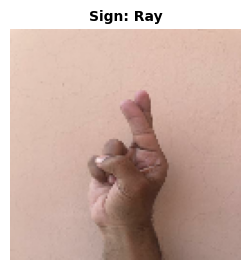


All notebook tasks completed successfully! All weights and diagrams are stored in your Google Drive folder: 'PSL_DeepLearning_Project'.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Side-by-Side Model Evaluation on Validation Set
print("--- Evaluating Model A (Custom CNN from Scratch) ---")
loss_a, acc_a = model_scratch.evaluate(val_ds)

print("\n--- Evaluating Model B (Transfer Learning MobileNetV2) ---")
loss_b, acc_b = model_transfer.evaluate(val_ds)

print("\n==================================================")
print(f" FINAL PERFORMANCE COMPARISON:")
print(f" Model A (Custom CNN) Accuracy:        {acc_a * 100:.2f}% (Loss: {loss_a:.4f})")
print(f" Model B (Transfer Learning) Accuracy: {acc_b * 100:.2f}% (Loss: {loss_b:.4f})")
print("==================================================\n")

# 2. Sample Inference / Prediction Test
for images, labels in val_ds.take(1):
    sample_image = images[0]
    sample_label = labels[0].numpy()
    break

# Run prediction on Model A
pred_a = model_scratch.predict(np.expand_dims(sample_image, axis=0), verbose=0)
pred_class_a = np.argmax(pred_a[0])
conf_a = np.max(pred_a[0]) * 100

# Run prediction on Model B
pred_b = model_transfer.predict(np.expand_dims(sample_image, axis=0), verbose=0)
pred_class_b = np.argmax(pred_b[0])
conf_b = np.max(pred_b[0]) * 100

print(f"--- Sample Test Results ---")
print(f"Ground Truth Class:  {class_names[sample_label]}")
print(f"Model A Prediction:  {class_names[pred_class_a]} ({conf_a:.2f}% confidence)")
print(f"Model B Prediction:  {class_names[pred_class_b]} ({conf_b:.2f}% confidence)")

# Display test image
plt.figure(figsize=(3, 3))
plt.imshow(sample_image.numpy().astype("uint8"))
plt.title(f"Sign: {class_names[sample_label]}", fontsize=10, weight='bold')
plt.axis('off')
plt.show()

print("\nAll notebook tasks completed successfully! All weights and diagrams are stored in your Google Drive folder: 'PSL_DeepLearning_Project'.")